# Project Q: splitting a chip with QAOA

Verilog → gate netlist → hypergraph → QUBO → (QAOA) → a split, scored classically.

We take a real circuit description, turn "cut this chip into two equal halves with as few wires crossing as possible" into an energy function a quantum algorithm can minimise, and check every answer with plain classical code. We make **no claim of quantum advantage**: on these sizes classical solvers win, and we report that.

## 1. The problem: balanced circuit partitioning

A design that is too big for one FPGA, or one die, has to be split across two. Every wire (net) that connects gates on both sides becomes a costly off-chip connection. So we want:

- **Small cut**: as few nets as possible span both halves.
- **Balance**: both halves hold about the same amount of logic, so each fits.

This is the classic *min-cut bisection* problem. It is NP-hard, which is why chip tools use heuristics (KaHyPar, hMETIS, Kernighan–Lin). It also maps naturally onto a QUBO, the input format of QAOA. We use the ISCAS-85 benchmark **c17**: 6 NAND gates, small enough to check every possible answer by hand.

## 2. The bridge: Verilog → netlist → hypergraph

**Yosys** (an open-source synthesis tool) turns the Verilog into a flat netlist of NAND gates: `synth -flatten; abc -g NAND; write_json`. We committed its output to `benchmarks/netlists/c17.json`, so this notebook runs **without Yosys installed**.

We read that JSON as a **hypergraph**:
- **node** = one gate;
- **net (hyperedge)** = one wire, joining *all* the gates it touches. One wire can feed 3 gates, which an ordinary graph edge (always 2 ends) can't express.

Wires that touch only one gate can never be cut, so they are dropped. An input pin that feeds two gates *does* count (c17's input N3 feeds two gates): if those gates land on different chips, the signal must reach both.

In [1]:
import shutil
import sys
from itertools import combinations
from pathlib import Path

# Works whether the notebook runs from notebooks/ or from the repo root.
ROOT = Path.cwd() if (Path.cwd() / "benchmarks").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # so `project_q` imports even if the package isn't pip-installed

from project_q.parse_yosys import is_balanced, load_hypergraph, load_netlist, run_yosys, true_cut
from project_q.qubo import build_partition_qubo, qubo_energy
from project_q.solvers import brute_force

hg = load_hypergraph(load_netlist(ROOT / "benchmarks" / "netlists" / "c17.json"))
print(f"{hg.num_nodes} gates: {hg.nodes}")
print(f"{len(hg.nets)} nets:")
for name, net in zip(hg.net_names, hg.nets):
    print(f"  {name:<8} joins {sorted(net)}")

6 gates: ['new_n8', 'new_n9', 'new_n10', 'N23', 'new_n12', 'N22']
5 nets:
  N3       joins ['new_n12', 'new_n8']
  new_n8   joins ['new_n10', 'new_n8', 'new_n9']
  new_n9   joins ['N22', 'N23', 'new_n9']
  new_n10  joins ['N23', 'new_n10']
  new_n12  joins ['N22', 'new_n12']


Yosys's optimiser (ABC) rebuilds the logic, so the original gate names (g10, g16, …) are gone. Each gate is labelled by the wire it drives (`N22`, `N23` are the outputs). The *structure* is the same as the hand-drawn c17 in `docs/research.md` (our tests check this with a graph isomorphism), so cuts are the same too.

If Yosys is installed, the next cell re-runs it live and confirms it gives the same hypergraph as the committed file.

In [2]:
if shutil.which("yosys"):
    live = load_hypergraph(run_yosys(ROOT / "benchmarks" / "c17.v"))
    print("Yosys found. Live run matches committed netlist:", live.nodes == hg.nodes and live.nets == hg.nets)
else:
    print("Yosys not installed: using the committed netlist (identical to a live run).")

Yosys not installed: using the committed netlist (identical to a live run).


**`true_cut`** is our ground truth: the number of nets with gates on both sides. It is a few lines of plain Python and shares no code with the QUBO, so a mistake in the quantum formulation can't hide itself. Below: all gates on one side (cut 0, but useless: not balanced) and one 3/3 split.

In [3]:
one_side = [0] * hg.num_nodes
split = [0, 0, 0, 1, 1, 1]  # first three gates on side A, rest on side B
for name, bits in [("all on one side", one_side), ("first 3 | last 3", split)]:
    print(f"{name:<17} cut = {true_cut(hg, bits)}, balanced = {is_balanced(hg, bits)}")

all on one side   cut = 0, balanced = False
first 3 | last 3  cut = 3, balanced = True


## 3. Problem → QUBO, checked against brute force

QAOA minimises an energy over bit strings. So we give each gate a bit, **x_i = 0 → side A, x_i = 1 → side B**, and write an energy whose minimum is the best split. A **QUBO** allows only linear and pairwise terms:

$$E(x) = \underbrace{\sum_{\text{nets}} \text{cut terms}}_{\text{wires crossing}} \; + \; \underbrace{\lambda \Big(\sum_i w_i x_i - \tfrac{W}{2}\Big)^2}_{\text{balance penalty}}$$

- **2-gate net {i, j}:** $x_i + x_j - 2x_ix_j$ is 1 exactly when the two bits differ.
- **3-gate net {i, j, k}:** $x_i + x_j + x_k - x_ix_j - x_jx_k - x_ix_k$ is 1 for any split of the three, 0 if all agree. Also exact.
- **Bigger nets (4–8 gates)** use a pair approximation (weight 1/(n−1) per pair), which over-counts even splits. c17 has none, and every answer is re-scored with `true_cut` anyway.
- **Balance:** a QUBO can't hold hard rules, so balance is a penalty that is 0 at a perfect 3/3 split. λ sets how much it costs to be lopsided.

**Check 1:** with λ = 0 (cut terms only), the energy must equal `true_cut` on *every* one of the 2⁶ = 64 bit strings.

In [4]:
cut_only = build_partition_qubo(hg, lam=0.0)
states = [[(k >> i) & 1 for i in range(hg.num_nodes)] for k in range(2 ** hg.num_nodes)]
matches = sum(qubo_energy(cut_only, s) == true_cut(hg, s) for s in states)
print(f"QUBO cut energy == true_cut on {matches}/{len(states)} assignments")

print("\nCut-only QUBO terms (i == j: linear term, i != j: pair term):")
for (i, j), c in sorted(cut_only.terms.items()):
    label = f"x[{hg.nodes[i]}]" if i == j else f"x[{hg.nodes[i]}]·x[{hg.nodes[j]}]"
    print(f"  {c:+.1f}  {label}")

QUBO cut energy == true_cut on 64/64 assignments

Cut-only QUBO terms (i == j: linear term, i != j: pair term):
  +2.0  x[new_n8]
  -1.0  x[new_n8]·x[new_n9]
  -1.0  x[new_n8]·x[new_n10]
  -2.0  x[new_n8]·x[new_n12]
  +2.0  x[new_n9]
  -1.0  x[new_n9]·x[new_n10]
  -1.0  x[new_n9]·x[N23]
  -1.0  x[new_n9]·x[N22]
  +2.0  x[new_n10]
  -2.0  x[new_n10]·x[N23]
  +2.0  x[N23]
  -1.0  x[N23]·x[N22]
  +2.0  x[new_n12]
  -2.0  x[new_n12]·x[N22]
  +2.0  x[N22]


**Check 2:** brute force over all 64 assignments at the default **λ = 2.0**. The lowest-energy state must be the best *balanced* split. Two numbers tell us the QUBO is safe to hand to a quantum solver:

- **energy gap ΔE**: how far the best wrong answer sits above the optimum. It must be > 0.
- **unbalanced margin**: how far the best *lopsided* split sits above the optimum. At λ = 1 it is 1.0; at λ = 2 it is 2.0. That wider energy margin is why the default is 2.0. It is a statement about energies only: our λ sweep shows QAOA doesn't sample better at λ = 2 (on c17, λ = 1 gives 68.6% balanced shots against 63.2%).

In [5]:
for lam in (1.0, 2.0):
    bf = brute_force(hg, build_partition_qubo(hg, lam=lam))
    print(
        f"λ = {lam}: best balanced cut {bf.best_cut}, lowest-energy state is optimal: {bf.argmin_is_optimal}, "
        f"ΔE = {bf.energy_gap:.1f}, unbalanced margin = {bf.unbalanced_margin:.1f}"
    )

qubo = build_partition_qubo(hg, lam=2.0)
best = brute_force(hg, qubo).best
side_a = [n for n, b in zip(hg.nodes, best.assignment) if b == 0]
side_b = [n for n, b in zip(hg.nodes, best.assignment) if b == 1]
print(f"\nOptimal split: A = {side_a} | B = {side_b}  (cut {best.cut}, balanced {best.balanced})")

λ = 1.0: best balanced cut 2, lowest-energy state is optimal: True, ΔE = 1.0, unbalanced margin = 1.0
λ = 2.0: best balanced cut 2, lowest-energy state is optimal: True, ΔE = 1.0, unbalanced margin = 2.0

Optimal split: A = ['new_n8', 'new_n12', 'N22'] | B = ['new_n9', 'new_n10', 'N23']  (cut 2, balanced True)


For the full picture: all C(6,3) = 20 balanced 3/3 splits, with their true cut and QUBO energy at λ = 2.0. They come in mirror pairs (A and B swapped), which have the same cut. Energy equals the cut on every row, because every c17 net has 2 or 3 gates. Only one split (and its mirror) reaches cut 2.

In [6]:
rows = []
for a in combinations(hg.nodes, 3):
    bits = [0 if n in a else 1 for n in hg.nodes]
    b = [n for n in hg.nodes if n not in a]
    rows.append((true_cut(hg, bits), qubo_energy(qubo, bits), a, b))
rows.sort()
print(f"{'side A':<26} {'side B':<26} cut  energy")
for cut, energy, a, b in rows:
    print(f"{', '.join(a):<26} {', '.join(b):<26} {cut:>3}  {energy:6.1f}")
print(f"\n{len(rows)} balanced splits")

side A                     side B                     cut  energy
new_n8, new_n12, N22       new_n9, new_n10, N23         2     2.0
new_n9, new_n10, N23       new_n8, new_n12, N22         2     2.0
N23, new_n12, N22          new_n8, new_n9, new_n10      3     3.0
new_n10, N23, N22          new_n8, new_n9, new_n12      3     3.0
new_n8, new_n10, N23       new_n9, new_n12, N22         3     3.0
new_n8, new_n10, new_n12   new_n9, N23, N22             3     3.0
new_n8, new_n9, new_n10    N23, new_n12, N22            3     3.0
new_n8, new_n9, new_n12    new_n10, N23, N22            3     3.0
new_n9, N23, N22           new_n8, new_n10, new_n12     3     3.0
new_n9, new_n12, N22       new_n8, new_n10, N23         3     3.0
new_n10, N23, new_n12      new_n8, new_n9, N22          4     4.0
new_n10, new_n12, N22      new_n8, new_n9, N23          4     4.0
new_n8, N23, new_n12       new_n9, new_n10, N22         4     4.0
new_n8, new_n9, N22        new_n10, N23, new_n12        4     4.0
new_n8, ne

**What this shows, and what it doesn't.** The QUBO encodes c17's partitioning problem exactly: its lowest energy is the true best balanced split, by a clear margin. It says nothing yet about whether QAOA *finds* that state; that is the next section. c17 is tiny, so brute force, simulated annealing and Kernighan–Lin all solve it instantly.

## 4. QUBO → Hamiltonian → QAOA (Phase 3)

A qubit reads Z = +1 or −1, not 0 or 1, so we substitute **x = (1 − z)/2** into the QUBO. The result is a **Hamiltonian**: the same energy formula written as Pauli Z terms, plus a constant offset. It's a diagonal matrix whose entries are the energies of the 64 splits.

`qiskit-addon-opt-mapper` does the conversion. It is at version 0.1.0, so we don't take it on trust. The next cell compares the Hamiltonian with `qubo_energy` on every state.

In [7]:
from project_q.solvers import qaoa, qubo_to_ising

operator, offset = qubo_to_ising(qubo)
# Qiskit's qubit 0 is the lowest bit of the state index, the same order as `states` above.
diagonal = operator.to_matrix().diagonal().real + offset
agree = sum(abs(diagonal[k] - qubo_energy(qubo, states[k])) < 1e-9 for k in range(len(states)))
print(f"{len(operator)} Pauli terms on {operator.num_qubits} qubits, offset {offset:.3f}")
print(f"Hamiltonian energy == QUBO energy on {agree}/{len(states)} basis states")

15 Pauli terms on 6 qubits, offset 6.000
Hamiltonian energy == QUBO energy on 64/64 basis states


**QAOA** is a short circuit with adjustable angles. It starts with every split equally likely. A cost layer (angle γ) marks states by their energy, then a mixer layer (angle β) moves probability toward low-energy states. **p** is how many times that pair repeats.

1. A classical optimizer (COBYLA) tunes the angles on the noise-free Aer simulator, from 20 random starts, to lower the average energy.
2. We measure the circuit 4000 times. Each shot is one split.
3. Our answer is the best **balanced** shot by `true_cut`, not the most frequent shot.

Finding cut 2 proves almost nothing here: 4000 uniform random shots on 64 states would almost surely include an optimum. So the next cell also compares the **rates** of good shots with uniform guessing, where 20/64 of states are balanced and 2/64 are optimal. This runs seed 0 only, at p=1 and p=2, and takes about half a minute.

In [8]:
BEST_C17 = brute_force(hg, qubo).best_cut
live_qaoa = {depth: qaoa(hg, qubo, p=depth, seed=0, best_known_cut=BEST_C17) for depth in (1, 2)}

print(f"{'':<18} {'mean energy':>11} {'balanced shots':>15} {'optimal shots':>14} {'best balanced cut':>18}")
print(f"{'uniform guessing':<18} {live_qaoa[1].info['uniform_energy']:>11.3f} {20 / 64:>15.2%} {2 / 64:>14.2%} {'not run':>18}")
for depth, result in live_qaoa.items():
    info = result.info
    cut = true_cut(hg, result.assignment)  # re-scored classically, never from the energy
    print(f"{f'QAOA p={depth}, seed 0':<18} {info['expected_energy']:>11.3f} {info['feasible_rate']:>15.2%} {info['p_optimal']:>14.2%} {cut:>18}")

                   mean energy  balanced shots  optimal shots  best balanced cut
uniform guessing         6.000          31.25%          3.12%            not run
QAOA p=1, seed 0         4.026          68.65%         10.15%                  2
QAOA p=2, seed 0         3.439          95.90%         16.95%                  2


One seed can mislead, so the next cell reads the 5 saved p=1 runs in `results/summary.csv`, the file behind every result table in this notebook. The notebook loads saved results instead of repeating them, because the full set of runs took about 42 minutes.

In [9]:
from project_q.experiments import ablation_verdict, read_rows

SUMMARY = read_rows(ROOT / "results" / "summary.csv")
print(f"{len(SUMMARY)} runs in results/summary.csv, {sum(r['status'] == 'ok' for r in SUMMARY)} finished without errors")

saved_qaoa = [r for r in SUMMARY if r["design"] == "c17" and r["solver"] == "qaoa"]
print(f"{'seed':>4} {'cut':>4} {'balanced shots':>15} {'optimal shots':>14}")
for r in saved_qaoa:
    print(f"{r['seed']:>4} {r['cut']:>4} {float(r['feasible_rate']):>15.2%} {float(r['p_optimal']):>14.2%}")
balanced_mean = sum(float(r['feasible_rate']) for r in saved_qaoa) / len(saved_qaoa)
optimal_mean = sum(float(r['p_optimal']) for r in saved_qaoa) / len(saved_qaoa)
print(f"mean {'':>9} {balanced_mean:>15.2%} {optimal_mean:>14.2%}")

210 runs in results/summary.csv, 210 finished without errors
seed  cut  balanced shots  optimal shots
   0    2          68.65%         10.15%
   1    2          67.58%          8.80%
   2    2          67.80%          8.97%
   3    2          68.23%         10.03%
   4    2          43.62%         11.15%
mean                    63.18%          9.82%


**Does p=2 help?** On c17, on average, yes. These 5-seed means aren't in `results/`. They come from `scripts/phase3_c17.py`, are recorded in `docs/DEFENSE.md`, and use the hand-written c17, whose qubit order differs from the Yosys netlist above. That's why its p=1 rates differ slightly from the table above.

| 5 seeds, 4000 shots | Mean energy | Balanced shots | Optimal shots | Found cut 2 |
|---|---|---|---|---|
| Uniform guessing | 6.000 | 31.2% | 3.1% | not run |
| QAOA p=1 | 4.217 | 62.4% | 9.2% | 5/5 |
| QAOA p=2 | 3.557 | 82.4% | 18.0% | 5/5 |

**What this shows, and what it doesn't.** The tuned circuit produces good splits more often than guessing does. That is a low bar. c17 is easy for every classical solver here, and this is a noise-free simulator. The optimizer also lowers average energy only, so lower energy doesn't guarantee more optimal shots: at p=2, seed 0 had lower energy than seed 2 but fewer optimal shots.

## 5. The scorecard (Phase 4)

A solver doesn't get to mark its own work. `make_record` takes a solver's final split and recomputes the cut and balance itself, so every solver is judged by the same rule. To demonstrate that, the next cell hands it a QAOA result that falsely reports cut 0. The record is printed here and not saved.

In [10]:
from dataclasses import replace

from project_q.scorecard import make_record

lying = replace(live_qaoa[1], cut=0)
record = make_record("c17", hg, lying, lam=2.0, eps=0.03, best_known_cut=BEST_C17, best_known_source="brute_force")
print(f"solver reported cut {lying.cut}; scorecard recorded cut {record.cut}")
for field in ("design", "solver", "k", "cut", "best_known_cut", "best_known_source", "gap_percent", "balance_ratio", "balanced", "qubits", "shots", "backend", "p", "seed"):
    print(f"  {field:<18} {getattr(record, field)}")

solver reported cut 0; scorecard recorded cut 2
  design             c17
  solver             qaoa
  k                  2
  cut                2
  best_known_cut     2
  best_known_source  brute_force
  gap_percent        0.0
  balance_ratio      1.0
  balanced           True
  qubits             6
  shots              4000
  backend            aer_simulator
  p                  1
  seed               0


Next, every solver that runs on the whole circuit, with no coarsening, on all three designs. c432 has 187 gates and c880 has 480. Each entry is the mean final cut (lowest–highest), and lower is better. These are saved runs with 5 seeds on c17 (brute force runs once, since it has no randomness) and 10 on the others, so optional KaHyPar doesn't need to be installed to read them.

- **Brute force and QAOA can't run on the two larger designs:** that would take 187 or 480 qubits, and our limit is 24.
- **Best cuts on c432 and c880 aren't proven.** Only c17's optimum is, by brute force.

In [11]:
def cuts_of(design, solver, target=""):
    return [r for r in SUMMARY if r["design"] == design and r["solver"] == solver and r["target"] == str(target)]


def cell(design, solver, target=""):
    runs = cuts_of(design, solver, target)
    if not runs:
        return "not possible" if not target else ""
    cuts = [int(r["cut"]) for r in runs]
    low, high = min(cuts), max(cuts)
    return f"{sum(cuts) / len(cuts):.1f} ({low}–{high})"


print(f"{'solver, whole circuit':<24} {'c17':>14} {'c432':>18} {'c880':>18}")
for solver in ("random", "sa", "kl", "kahypar", "brute", "qaoa"):
    print(f"{solver:<24} {cell('c17', solver):>14} {cell('c432', solver):>18} {cell('c880', solver):>18}")

solver, whole circuit               c17               c432               c880
random                        3.6 (3–4)    113.2 (102–124)    299.4 (282–313)
sa                            2.0 (2–2)       13.8 (13–15)       25.7 (23–29)
kl                            2.0 (2–2)       19.1 (18–21)       41.4 (27–57)
kahypar                       2.0 (2–2)       11.0 (11–11)       21.6 (21–24)
brute                         2.0 (2–2)       not possible       not possible
qaoa                          2.0 (2–2)       not possible       not possible


## 6. Reaching larger circuits: multilevel (Phase 5)

c432 has 187 gates, far more than we can simulate. So we shrink it, solve the small version, and grow the answer back:

1. **Coarsen:** repeatedly merge pairs of gates that share the most wires into heavier "supernodes", until 12 or 20 remain.
2. **Solve** the small version with any solver: QAOA, simulated annealing, random or brute force.
3. **Uncoarsen and refine:** undo the merges one level at a time. After each level, **FM** (Fiduccia–Mattheyses) moves single nodes across when that lowers the cut, while keeping the split balanced.

Merging can't change the cost of a split: a net cut in the small circuit is the same net cut in the original. The next cell checks that on a random split at every level.

In [12]:
import random

from project_q.coarsen import coarsen, fm_refine, project
from project_q.experiments import load_benchmark
from project_q.parse_yosys import side_weights

c432 = load_benchmark("c432")
hierarchy = coarsen(c432, target=12, seed=0)
print(f"c432: {c432.num_nodes} gates, {len(c432.nets)} nets, coarsened to {hierarchy.coarsest.num_nodes} supernodes over {len(hierarchy.levels) - 1} merging rounds")
print(f"supernode weights: {sorted(hierarchy.coarsest.weights.values())}")

rng = random.Random(0)
bits = [rng.randint(0, 1) for _ in hierarchy.coarsest.nodes]
print("A random coarse split, opened up one level at a time:")
print(f"  {hierarchy.coarsest.num_nodes:>4} nodes: cut {true_cut(hierarchy.coarsest, bits)}, side weights {side_weights(hierarchy.coarsest, bits)}")
for level in range(len(hierarchy.levels) - 2, -1, -1):
    bits = project(bits, hierarchy.levels[level + 1], hierarchy.levels[level], hierarchy.maps[level])
    print(f"  {hierarchy.levels[level].num_nodes:>4} nodes: cut {true_cut(hierarchy.levels[level], bits)}, side weights {side_weights(hierarchy.levels[level], bits)}")

c432: 187 gates, 200 nets, coarsened to 12 supernodes over 5 merging rounds
supernode weights: [4, 12, 13, 15, 15, 16, 16, 17, 17, 20, 20, 22]
A random coarse split, opened up one level at a time:
    12 nodes: cut 22, side weights (53, 134)
    18 nodes: cut 22, side weights (53, 134)
    31 nodes: cut 22, side weights (53, 134)
    57 nodes: cut 22, side weights (53, 134)
   103 nodes: cut 22, side weights (53, 134)
   187 nodes: cut 22, side weights (53, 134)


Now the whole pipeline on c432 at seed 0, first with a **random** coarse split and then with **QAOA** (p=1, 12 qubits, about 20 s). Each line of the trace shows one level, with its cut before and after FM. Watch how much of the drop happens after the coarse solver has finished. The last line compares the live QAOA run with the saved row in `summary.csv`.

In [13]:
from project_q.coarsen import multilevel

live_multilevel = {name: multilevel(c432, name, target=12, seed=0) for name in ("random", "qaoa")}
for name, result in live_multilevel.items():
    info = result.info
    print(f"{name}+FM: coarse cut {info['coarse_cut']} → final cut {true_cut(c432, result.assignment)}, balanced {result.balanced}, λ = {info['lam']:.3f} ({info['lam_source']})")
    for step in info["levels"]:
        print(f"  {step['nodes']:>4} nodes: cut {step['cut_before_fm']:>3} → {step['cut_after_fm']:>3} after FM")

saved = next(r for r in cuts_of("c432", "multilevel-qaoa", 12) if r["seed"] == "0")
same = "".join(map(str, live_multilevel["qaoa"].assignment)) == saved["assignment"]
print(f"Live QAOA+FM split matches the saved seed 0 row (cut {saved['cut']}): {same}")

random+FM: coarse cut 28 → final cut 11, balanced True, λ = 0.736 (rule)
    12 nodes: cut  28 →  28 after FM
    18 nodes: cut  28 →  28 after FM
    31 nodes: cut  28 →  28 after FM
    57 nodes: cut  28 →  12 after FM
   103 nodes: cut  12 →  11 after FM
   187 nodes: cut  11 →  11 after FM
qaoa+FM: coarse cut 21 → final cut 12, balanced True, λ = 0.736 (rule)
    12 nodes: cut  21 →  21 after FM
    18 nodes: cut  21 →  21 after FM
    31 nodes: cut  21 →  21 after FM
    57 nodes: cut  21 →  13 after FM
   103 nodes: cut  13 →  12 after FM
   187 nodes: cut  12 →  12 after FM
Live QAOA+FM split matches the saved seed 0 row (cut 12): True


FM has a blind spot: it moves one node at a time. On c17 every move from a 3/3 split gives 2/4, which breaks the balance rule, so it has no legal move at all. That's why c17 stays flat, with no multilevel rows. The next cell starts FM from c17's worst balanced split to show this.

In [14]:
worst = max((s for s in states if is_balanced(hg, s)), key=lambda s: true_cut(hg, s))
refined, improving_passes = fm_refine(hg, worst)
print(f"c17 from its worst balanced split: cut {true_cut(hg, worst)} → {true_cut(hg, refined)} after FM, {improving_passes} improving passes (best possible: {BEST_C17})")

c17 from its worst balanced split: cut 5 → 5 after FM, 0 improving passes (best possible: 2)


**Gate 2: does QAOA match brute force on about 12 qubits?** Yes, but that proves little. These numbers aren't in `results/`. They come from `scripts/gate2_c432.py` (about 25 minutes) and are recorded in `docs/DEFENSE.md`. c432 is coarsened to 12 nodes with 3 coarsening seeds and 5 QAOA seeds each. "Guessing" sends 4000 uniform random shots through the same selection rule.

| Instance | Best cut | QAOA matched | Guessing matched | Optimal shots: QAOA vs guessing | Balanced shots: QAOA vs guessing | Optimal share of balanced shots: QAOA vs guessing |
|---|---|---|---|---|---|---|
| Seed 0 | 21 | 5/5 | 5/5 | 0.350% vs 0.146% | 14.8% vs 6.9% | 2.36% vs 2.13% |
| Seed 1 | 12 | 5/5 | 4/5 | 0.120% vs 0.049% | 21.8% vs 8.9% | 0.55% vs 0.55% |
| Seed 2 | 16 | 5/5 | 5/5 | 0.090% vs 0.049% | 16.6% vs 6.9% | 0.54% vs 0.71% |

**Verdict.** Gate 2 passed as written: QAOA's best shot equalled brute force in 15 of 15 runs. But guessing matched in 14 of 15, because 4000 shots nearly cover 4096 states. Our stricter test, fixed before running, passed on 2 of 3 instances at p=1. QAOA learned to produce balanced splits, but not lower cuts: the last column shows no real gain once a shot is balanced. **So we have no evidence that QAOA finds better cuts than random sampling at this size.**

## 7. Benchmarks and ablation (Phase 6)

All the c432 and c880 runs together. Multilevel rows are named by their coarse solver, and each went through coarsening to 12 or 20 supernodes, then FM. The 12-supernode rows use 10 seeds, the 20-supernode rows only 3. QAOA is p=1 on the noise-free Aer simulator, with 20 restarts and 4000 shots. The last columns are mean runtime in seconds, and they will differ on other machines.

In [15]:
def seconds(design, solver, target=""):
    runs = cuts_of(design, solver, target)
    return f"{sum(float(r['runtime_s']) for r in runs) / len(runs):.2f}" if runs else ""


print(f"{'solver':<20} {'supernodes':>10} {'c432 cut':>18} {'c880 cut':>18} {'c432 s':>8} {'c880 s':>8}")
for solver in ("random", "sa", "kl", "kahypar"):
    print(f"{solver:<20} {'flat':>10} {cell('c432', solver):>18} {cell('c880', solver):>18} {seconds('c432', solver):>8} {seconds('c880', solver):>8}")
for target in (12, 20):
    for solver in ("random", "sa", "brute", "qaoa"):
        name = f"multilevel-{solver}"
        print(f"{name:<20} {target:>10} {cell('c432', name, target):>18} {cell('c880', name, target):>18} {seconds('c432', name, target):>8} {seconds('c880', name, target):>8}")

solver               supernodes           c432 cut           c880 cut   c432 s   c880 s
random                     flat    113.2 (102–124)    299.4 (282–313)     0.00     0.00
sa                         flat       13.8 (13–15)       25.7 (23–29)     0.51     1.51
kl                         flat       19.1 (18–21)       41.4 (27–57)     0.00     0.01
kahypar                    flat       11.0 (11–11)       21.6 (21–24)     0.01     0.03
multilevel-random            12       13.5 (11–16)       25.0 (21–30)     0.01     0.08
multilevel-sa                12       11.5 (11–12)       26.2 (21–32)     0.04     0.10
multilevel-brute             12       11.7 (11–14)       26.1 (21–31)     0.01     0.08
multilevel-qaoa              12       11.5 (11–12)       26.2 (21–32)    17.93    23.55
multilevel-random            20       12.3 (11–14)       28.0 (26–30)     0.01     0.06
multilevel-sa                20       11.0 (11–11)       28.7 (24–33)     0.05     0.12
multilevel-brute             20 

An **ablation** swaps out one part of a pipeline to see how much that part matters. We keep coarsening and FM fixed and change only the solver in the middle. The same seed gives every solver the same coarse circuit, so runs can be compared in pairs.

We fixed the wording rule before running: "beat" needs a lower mean **and** a sign test below p = 0.05. The sign test ignores ties and asks whether QAOA wins more seeds than a fair coin would. The next cell recomputes the verdicts from the CSV and checks them against the saved file. It then shows how far FM moves each solver's coarse cut.

Random+FM matches QAOA+FM. c432, 12 supernodes, 10 seeds: mean final cut random+FM 13.5, QAOA+FM 11.5; QAOA lower on 6, tied on 2, random lower on 2; sign test p = 0.289.
Descriptive only, 3 seeds can't reach p < 0.05. c432, 20 supernodes, 3 seeds: mean final cut random+FM 12.3, QAOA+FM 12.7; QAOA lower on 2, tied on 0, random lower on 1; sign test p = 1.000.
Random+FM matches QAOA+FM. c880, 12 supernodes, 10 seeds: mean final cut random+FM 25.0, QAOA+FM 26.2; QAOA lower on 1, tied on 4, random lower on 5; sign test p = 0.219.
Descriptive only, 3 seeds can't reach p < 0.05. c880, 20 supernodes, 3 seeds: mean final cut random+FM 28.0, QAOA+FM 28.7; QAOA lower on 1, tied on 0, random lower on 2; sign test p = 1.000.
Recomputed verdicts match results/ablation_verdict.txt: True

12 supernodes     c432 coarse → final    c880 coarse → final
random                    28.6 → 13.5            61.0 → 25.0
sa                        16.1 → 11.5            45.3 → 26.2
brute                     15.7 

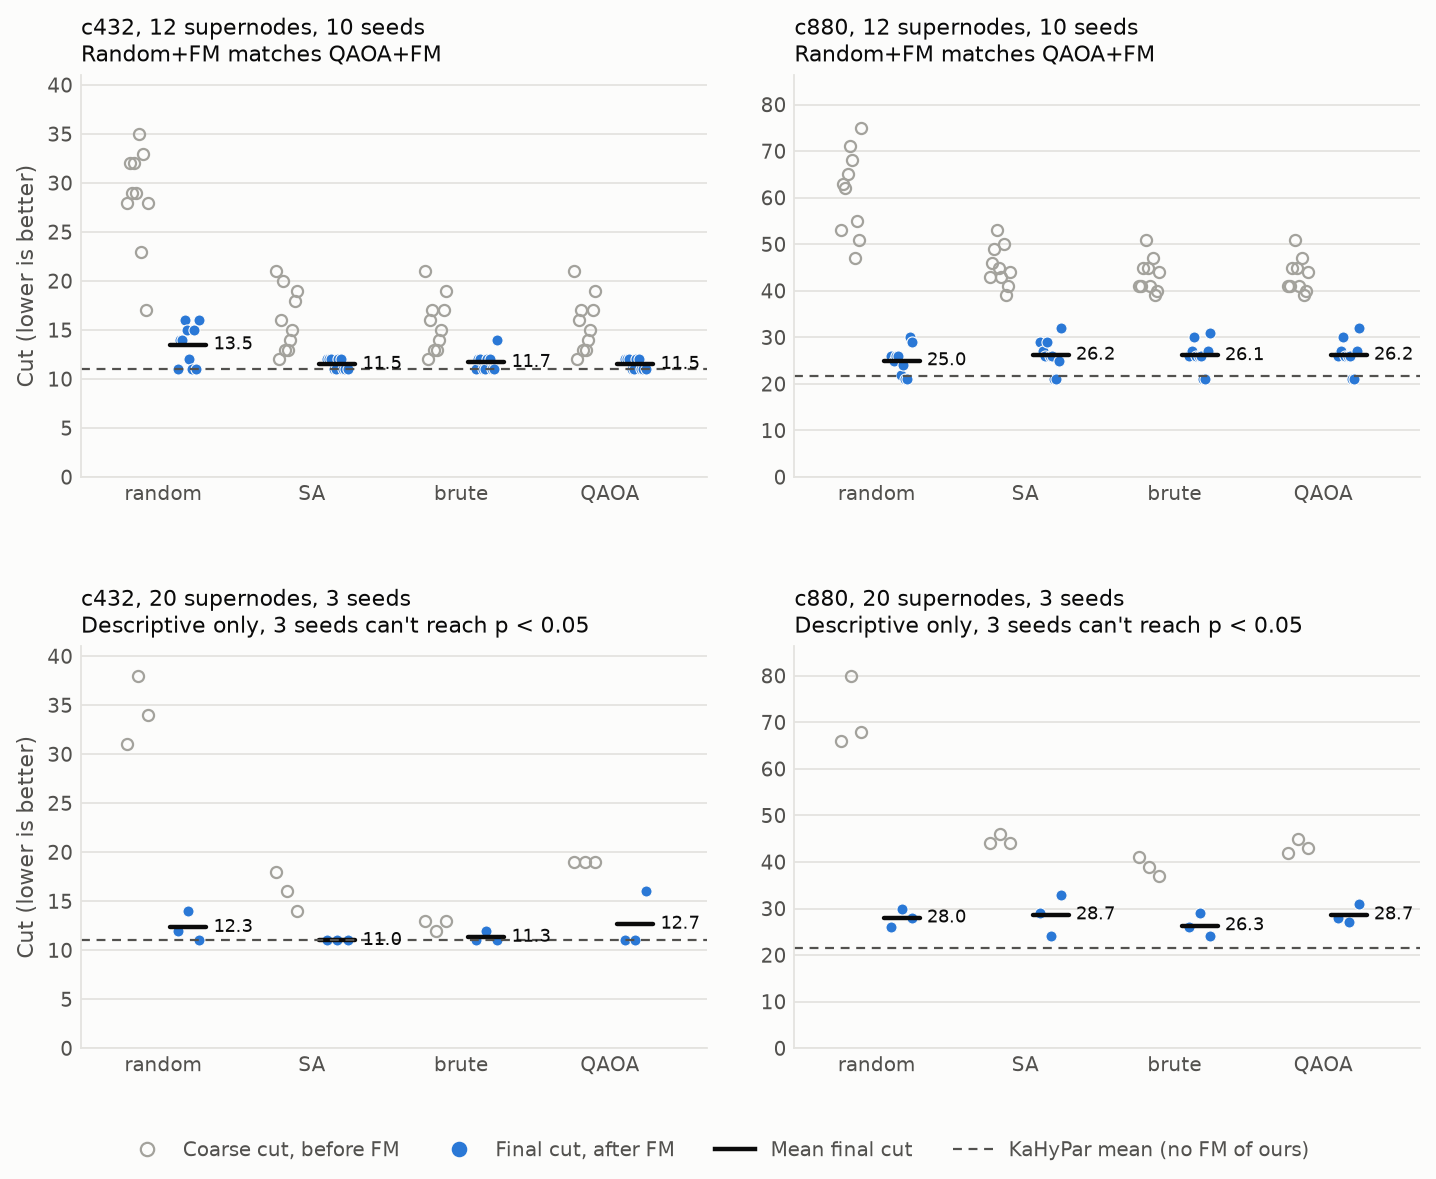

In [16]:
from IPython.display import Image, display

saved_verdicts = (ROOT / "results" / "ablation_verdict.txt").read_text(encoding="utf-8").splitlines()
verdicts = [ablation_verdict(SUMMARY, design, target) for design in ("c432", "c880") for target in (12, 20)]
for verdict in verdicts:
    print(verdict.sentence)
print("Recomputed verdicts match results/ablation_verdict.txt:", [v.sentence for v in verdicts] == saved_verdicts)
print()

print(f"{'12 supernodes':<14} {'c432 coarse → final':>22} {'c880 coarse → final':>22}")
for solver in ("random", "sa", "brute", "qaoa"):
    parts = []
    for design in ("c432", "c880"):
        runs = cuts_of(design, f"multilevel-{solver}", 12)
        parts.append(f"{sum(int(r['coarse_cut']) for r in runs) / len(runs):.1f} → {sum(int(r['cut']) for r in runs) / len(runs):.1f}")
    print(f"{solver:<14} {parts[0]:>22} {parts[1]:>22}")
print()

for target in (12, 20):
    pairs = [(q, b) for design in ("c432", "c880")
             for q in cuts_of(design, "multilevel-qaoa", target)
             for b in cuts_of(design, "multilevel-brute", target) if q["seed"] == b["seed"]]
    matched = sum(q["coarse_cut"] == b["coarse_cut"] for q, b in pairs)
    print(f"QAOA's best shot equals brute force's coarse cut at {target} qubits: {matched} of {len(pairs)} runs")

display(Image(filename=str(ROOT / "plots" / "ablation.png")))

**What the ablation shows.**

- **FM does most of the work.** It turns even a random coarse split into a good final cut.
- **A better coarse cut doesn't reliably give a better final cut.** On c880 at 12 supernodes, brute force has the best possible coarse cuts, yet random's far worse ones end slightly lower.
- **Random+FM matches QAOA+FM** by our rule, on both designs at 12 supernodes. "Matches" means this test found no clear difference. It doesn't prove they are equal: on c432 QAOA's mean is lower and it wins more seeds, but 10 seeds couldn't confirm that, and the comparison leans the other way on c880.
- **QAOA's coarse answers depend on size.** The 12-qubit matches say little, since 4000 shots nearly cover 4096 states. At 20 qubits, where 4000 shots can't cover about a million states, it never reached the coarse optimum.
- **Classical tools are ahead.** On c432 at 12 supernodes, simulated annealing+FM has the same final cuts as QAOA+FM on all 10 seeds, about 500 times faster. KaHyPar alone is at least as good as every multilevel row's mean.

**Choosing λ without brute force.** λ sets how strongly the QUBO punishes uneven splits. Fixed λ = 2.0 suits c17 but not heavy supernodes. `suggest_lambda` computes it from the circuit alone: λ = d̄ / (δ_out² − δ_min²), where d̄ is the average number of nets per node, δ_min the smallest possible imbalance, and δ_out the first imbalance the balance rule rejects. So going from the most even split to the first illegal one costs about as much as the wires on a typical node.

The score below asks whether the QUBO's lowest-energy state is the true best split, using brute force only to mark the answer. The formula was chosen after seeing the 4 "known" instances, so **only the held-out group counts as evidence**.

In [17]:
from project_q.qubo import suggest_lambda

print(f"suggest_lambda on c17 = {suggest_lambda(hg)} (Gate 1 still holds at this value)")
RULE = read_rows(ROOT / "results" / "lambda_rule.csv")


def rule_score(rows, column):
    return f"{sum(r[column] == 'True' for r in rows)}/{len(rows)}"


groups = [("Used to choose the formula, not evidence", [r for r in RULE if r["group"] == "known"]),
          ("Held out: all", [r for r in RULE if r["group"] == "held_out"])]
for design, target in (("c432", "12"), ("c880", "12"), ("c432", "20"), ("c880", "20")):
    groups.append((f"Held out: {design}, {target} supernodes",
                   [r for r in RULE if r["group"] == "held_out" and r["design"] == design and r["target"] == target]))

print(f"{'lowest-energy state is the true best split':<44} {'rule':>6} {'λ = 2.0':>8}")
for label, group in groups:
    print(f"{label:<44} {rule_score(group, 'rule_min_is_optimal'):>6} {rule_score(group, 'fixed2_min_is_optimal'):>8}")

suggest_lambda on c17 = 2.0 (Gate 1 still holds at this value)
lowest-energy state is the true best split     rule  λ = 2.0
Used to choose the formula, not evidence        4/4      2/4
Held out: all                                 11/23     8/23
Held out: c432, 12 supernodes                   5/7      4/7
Held out: c880, 12 supernodes                  3/10     2/10
Held out: c432, 20 supernodes                   2/3      1/3
Held out: c880, 20 supernodes                   1/3      1/3


**The λ sweep.** Does the choice of λ change what QAOA actually samples? We ran QAOA p=1 at six values of λ with 5 seeds each, on c17 and on one coarsened c432 instance. That instance (seed 1) was chosen openly, because λ = 2.0 is known to fail there. Each row is the mean over the 5 seeds, followed by the plot.

c17 (best cut 2, rule λ = 2.00)
     λ  lowest-energy cut  balanced shots  optimal shots  mean balanced-shot cut
   0.1                  0          17.89%          9.52%                     2.5
   0.3                  2          27.67%         13.05%                     2.6
   1.0                  2          68.57%         14.07%                     3.1
   2.0                  2          63.18%          9.82%                     3.3
   3.0                  2          58.48%         19.18%                     2.8
  10.0                  2          65.59%         10.59%                     3.4
c432-coarse-12-s1 (best cut 12, rule λ = 0.75)
     λ  lowest-energy cut  balanced shots  optimal shots  mean balanced-shot cut
   0.1                 12          21.93%          0.12%                    27.3
   0.3                 12          22.13%          0.15%                    27.4
   1.0                 12          22.01%          0.14%                    27.5
   2.0                 19     

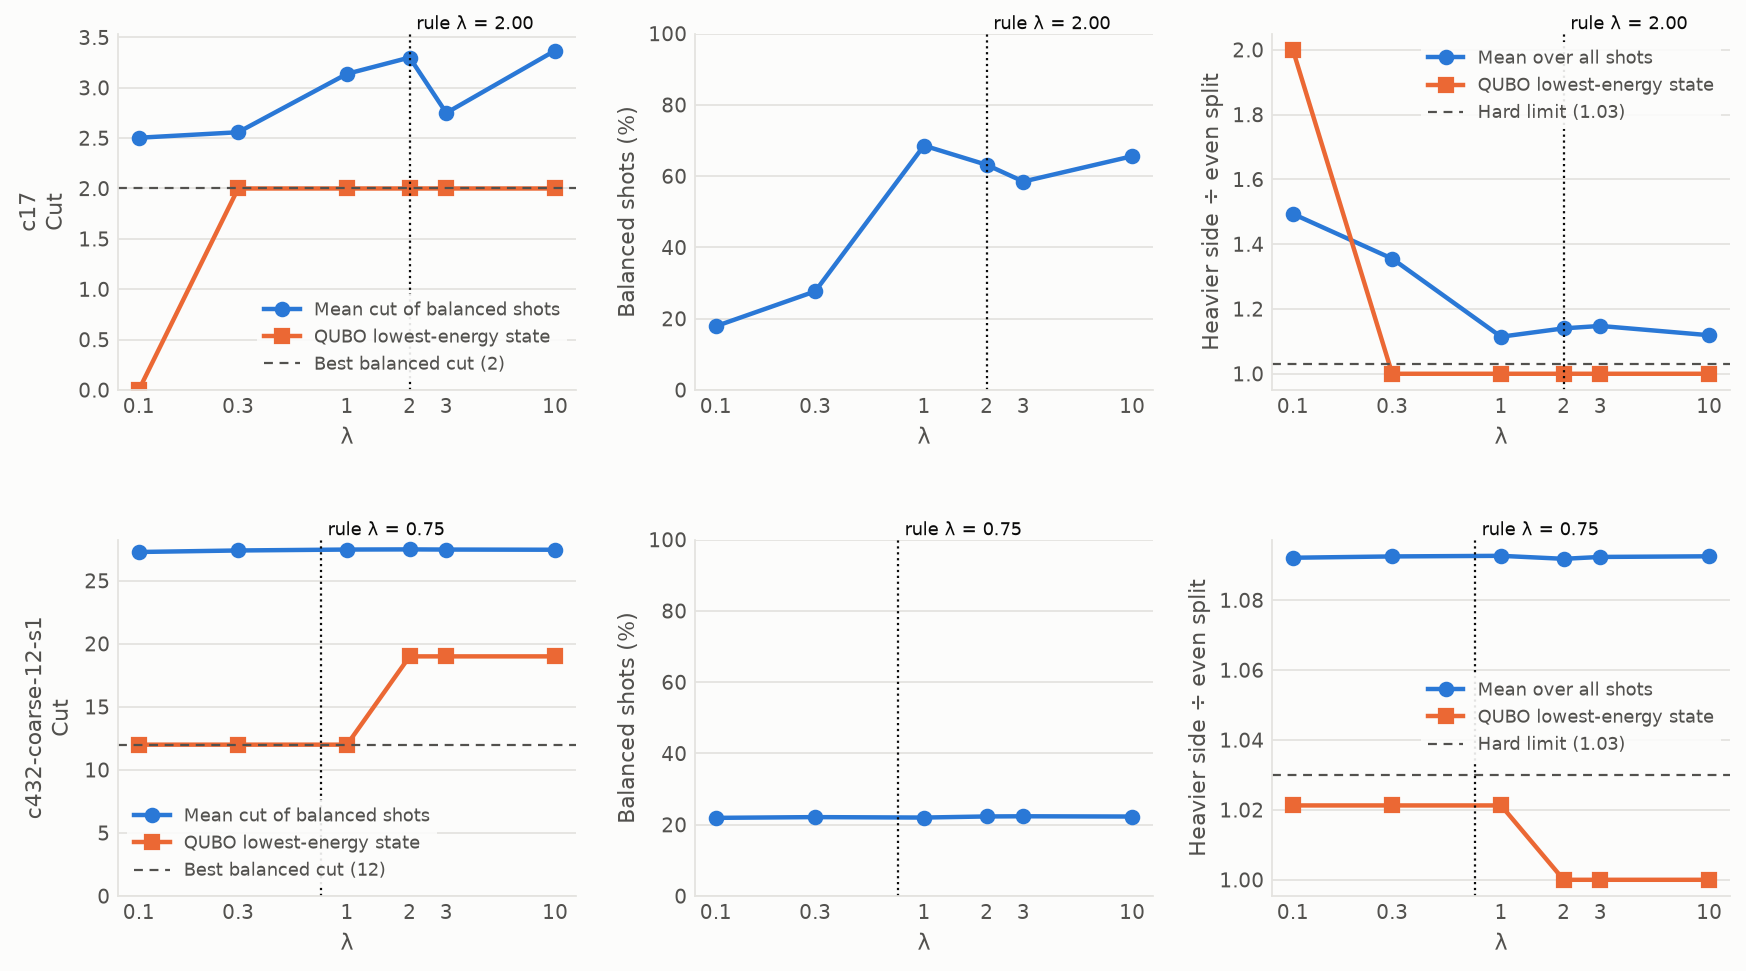

In [18]:
SWEEP = read_rows(ROOT / "results" / "lambda_sweep.csv")


def sweep_mean(rows, column):
    return sum(float(r[column]) for r in rows) / len(rows)


for instance in dict.fromkeys(r["instance"] for r in SWEEP):
    rows_here = [r for r in SWEEP if r["instance"] == instance]
    print(f"{instance} (best cut {rows_here[0]['best_known_cut']}, rule λ = {float(rows_here[0]['rule_lambda']):.2f})")
    print(f"{'λ':>6} {'lowest-energy cut':>18} {'balanced shots':>15} {'optimal shots':>14} {'mean balanced-shot cut':>23}")
    for lam in dict.fromkeys(r["lambda"] for r in rows_here):
        at_lam = [r for r in rows_here if r["lambda"] == lam]
        print(f"{float(lam):>6} {at_lam[0]['qubo_min_cut']:>18} {sweep_mean(at_lam, 'feasible_rate'):>15.2%} "
              f"{sweep_mean(at_lam, 'p_optimal'):>14.2%} {sweep_mean(at_lam, 'mean_balanced_shot_cut'):>23.1f}")

display(Image(filename=str(ROOT / "plots" / "lambda_sweep.png")))

**What this shows.**

- **The rule is better than fixed λ = 2.0, but it isn't solved.** Its lowest-energy state is the true best split on under half of the held-out instances.
- **A better QUBO hasn't meant better QAOA samples.** On coarse c432, the lowest-energy state changes with λ, but the rates of balanced and optimal shots barely move. The likely reason is that supernode weights make the balance term far larger than the cut terms even at λ = 0.1, and normalizing removes the overall scale. We haven't tested that separately.

Last, the partition picture: c17's proven-optimal split, with its 2 cut nets in black.

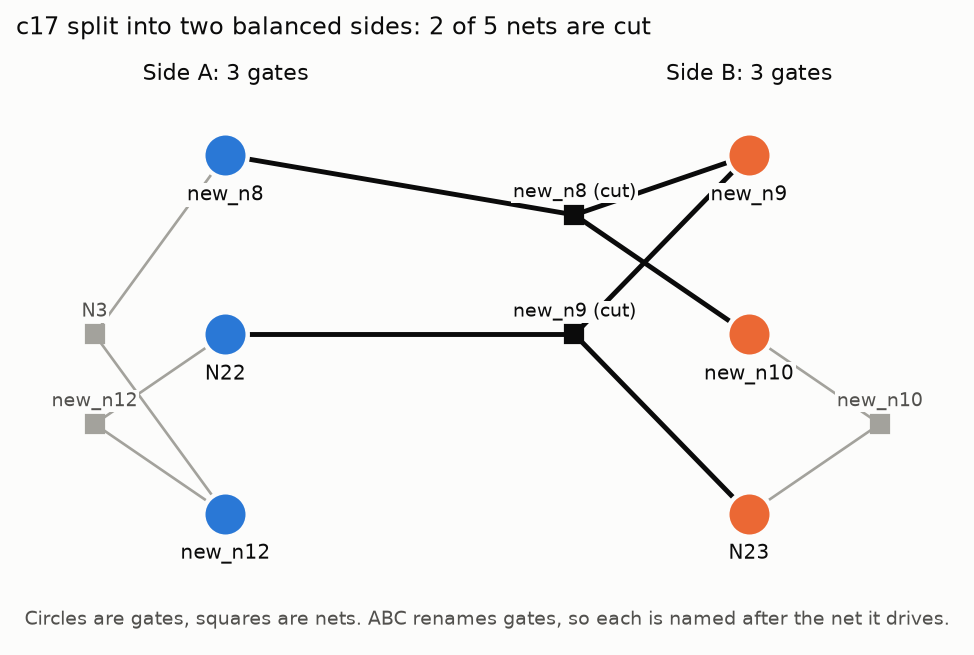

In [19]:
display(Image(filename=str(ROOT / "plots" / "partition_c17.png")))

## 8. Limitations

**We make no claim of quantum advantage. Classical tools win at this size.**

**The main results**
- **Classical wins.** KaHyPar alone beats or ties every multilevel mean on both designs, in 0.03 s or less. QAOA+FM takes about 18 s to 250 s per run.
- **FM does most of the work.** Random+FM matches QAOA+FM by the rule we fixed in advance.
- **QAOA learned balance, not better cuts.** Among balanced shots, it hits the optimum about as often as guessing does (Gate 2).
- **At 20 qubits QAOA reached the coarse optimum in 0 of 6 runs.** We didn't run uniform guessing at that size, so we can't compare its shots with guessing there.

**Known limitations** (from `docs/DEFENSE.md`)
1. **λ = 2.0 doesn't suit weighted supernodes. Partly fixed.** On 2 of the 3 coarsened c432 instances from Phase 5, its lowest-energy state isn't the best balanced split (cut 19 vs 12, cut 23 vs 16). `suggest_lambda` needs no brute force and improves on 2.0, but its lowest-energy state is optimal on only 11 of 23 held-out instances, and it doesn't change what QAOA samples on the instance we swept.
2. **FM can get stuck when balance is tight. Still open.** FM moves one node at a time, so on c17 no move is legal from a 3/3 split. It works on c432 because the rule allows sides from 91 to 96. FM can't guarantee balance when supernodes are too heavy to fit; the result would report that.
3. **The CLI didn't use multilevel. Fixed in Phase 6.** `partition` and `benchmark` now send designs above 24 nodes through multilevel.

**The formulation**
- **The QUBO is approximate on large nets.** 4–8-gate nets use a pair rule that over-scores even splits, and nets above 8 gates are left out of the QUBO. Lowest energy may therefore not be lowest cut. Every answer is re-scored with `true_cut`.
- **Balance is soft in the QUBO and hard in scoring.** On weighted supernodes the penalty can push away from splits the hard rule accepts.

**The evidence**
- **Small and narrow.** Two larger circuits, p=1 in the benchmarks, at most 20 qubits, and only 3 seeds at 20 supernodes, so those rows only describe what happened.
- **The comparison isn't even-handed.** Random+FM uses one random split, while QAOA gets its best of 4000 checked shots, which favours QAOA. Solvers weren't tuned, and we applied no correction for testing several designs and sizes.
- **Best known cuts on c432 and c880 aren't proven optimal.** They are the best in this file. Only c17's optimum is proven.
- **The netlists aren't the original ISCAS-85 files.** They were re-synthesized twice, so our cuts can't be compared directly with published results.
- **c17 proves very little.** It is tiny, and every solver except a single random split finds its optimum.

**Hardware**
- **Everything here ran on the noise-free Aer simulator.** Hardware results could be much worse.
- **No IBM hardware job has been run.** `scripts/hardware_c17.py` is built and tested against stubs only, and this notebook contains no hardware numbers.

**What we do claim:** a working bridge from Verilog to a quantum-ready optimization problem, and an honest scorecard that compares it with classical solvers using one classical scoring rule.